# Web Sentiment Index · Midterm Final
**20210673 · Kim Daeho**

저장된 원자료와 확정 명세의 재현용 코드이다. 자료·방법(1–5), 분석 결과(6–9), 검증(10) 순서로 정리했다.
새로이 분석·설계 변경·자료 수집은 수행하지 않는다.

## 0. Environment and Project Setup
프로젝트 폴더 또는 그 상위 폴더에서 실행한다. 필요한 패키지와 로컬 NLTK 자원은 미리 설치되어 있어야 한다.
자동 설치·네트워크 요청 없이 고정 시드 42와 상대 경로를 사용한다.

In [1]:
from pathlib import Path
from collections import Counter
import hashlib, importlib.metadata, json, random, sys

sys.dont_write_bytecode = True
candidates = [Path.cwd(), Path.cwd() / "midterm paper", Path.cwd().parent]
PROJECT = next((p.resolve() for p in candidates
                if (p / "FINAL_PREPROCESSING_POLICY.json").exists()
                and (p / "data/raw/news/guardian_full/articles").is_dir()), None)
if PROJECT is None:
    raise FileNotFoundError("프로젝트의 midterm paper 폴더에서 실행하세요. 로컬 원자료가 필요합니다.")
sys.path.insert(0, str(PROJECT))
if (PROJECT / ".packages").is_dir():
    sys.path.insert(0, str(PROJECT / ".packages"))

import numpy as np
import pandas as pd
import requests
import pyarrow.dataset as ds
import nltk
import matplotlib.pyplot as plt
from scipy.stats import linregress
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from IPython.display import display, Image, Markdown
%matplotlib inline

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
START, END = pd.Timestamp("2017-01-01"), pd.Timestamp("2026-10-25")
NETWORK_COLLECTION_ENABLED = False
FLAGS = {"broad_business_control": "in_broad_business_control",
         "anchors_stock_market_tag": "in_anchors_stock_market_tag"}
ALIASES = {"broad_business_control": "broad", "anchors_stock_market_tag": "strict"}
package_names = ["pandas", "numpy", "requests", "pyarrow", "nltk", "vaderSentiment",
                 "matplotlib", "scipy", "wordcloud", "exchange_calendars",
                 "beautifulsoup4", "regex"]
versions = pd.DataFrame({"package": package_names,
                        "version": [importlib.metadata.version(p) for p in package_names]})
print("Python", sys.version.split()[0], "| Project:", PROJECT.name, "| Seed:", SEED)
display(versions)

used_files = set()
input_hashes = {}
def use_file(relative):
    path = PROJECT / relative
    if not path.is_file():
        raise FileNotFoundError(f"필수 로컬 입력 파일 없음: {relative}; 자동 다운로드하지 않습니다.")
    used_files.add(str(path.relative_to(PROJECT)))
    input_hashes.setdefault(str(path.relative_to(PROJECT)), hashlib.sha256(path.read_bytes()).hexdigest())
    return path

def read_table(relative, **kwargs):
    return pd.read_csv(use_file(relative), float_precision="round_trip", **kwargs)

def read_json(relative):
    return json.loads(use_file(relative).read_text(encoding="utf-8"))

def load_parquet(relative, columns=None):
    folder = PROJECT / relative
    paths = sorted(folder.rglob("*.parquet"))
    if not paths:
        raise FileNotFoundError(f"필수 로컬 Parquet 없음: {relative}")
    for path in paths:
        use_file(path.relative_to(PROJECT))
    return ds.dataset(folder, format="parquet", partitioning="hive").to_table(columns=columns).to_pandas()

def show_figure(relative, width=1000):
    display(Image(filename=str(use_file(relative)), width=width))

def assert_close(actual, expected, label, atol=1e-12):
    if not np.allclose(actual, expected, atol=atol, rtol=1e-10, equal_nan=True):
        raise AssertionError(f"최종 결과와 불일치: {label}")

pd.set_option("display.max_colwidth", 100)
pd.set_option("display.float_format", lambda value: f"{value:.7g}")

Python 3.10.21 | Project: midterm paper | Seed: 42


,package,version
0,pandas,2.3.3
1,numpy,2.2.5
2,requests,2.34.2
3,pyarrow,25.0.1
4,nltk,3.10.0
5,vaderSentiment,3.3.2
6,matplotlib,3.10.9
7,scipy,1.15.3
8,wordcloud,1.9.6
9,exchange_calendars,4.13.2


## 1. Guardian Data · Data Collection Reference
목표 기간은 **2017-01-01~2026-10-25**이다. Broad를 주 자료, stock-market tag를 엄격 강건성 자료로 사용한다.
공식 Guardian Content API로 과거에 수집한 원자료를 로컬 Parquet로 보존했다.
아래 코드는 사용한 쿼리 구성만 보여 준다. 인증값을 읽거나 페이지 수집을 실행하지 않는다.
원래 수집 함수: `guardian_full_collection.py`의 `request_params`·`collect`.

In [2]:
use_file("guardian_api_config.py")
use_file("guardian_full_collection.py")
from guardian_api_config import STRATEGIES, window_params

def guardian_query_parameters(strategy, page=1):
    # Parameters only: no HTTP request, authentication, or pagination execution.
    return {**STRATEGIES[strategy], **window_params("2017-01-01", "2026-10-25"),
            "page-size": 200, "page": page, "order-by": "oldest", "use-date": "published",
            "show-fields": "headline,trailText,productionOffice", "show-tags": "all"}

query_table = pd.DataFrame([{"strategy": strategy,
                            "role": "primary" if ALIASES[strategy] == "broad" else "robustness",
                            **guardian_query_parameters(strategy)} for strategy in FLAGS])
display(query_table[["strategy", "role", "q", "section", "tag", "from-date", "to-date", "page-size"]].fillna(""))

,strategy,role,q,section,tag,from-date,to-date,page-size
0,broad_business_control,primary,"stocks OR equities OR ""Wall Street"" OR ""S&P 500"" OR Nasdaq OR ""Dow Jones""",business,,2017-01-01,2026-10-26,200
1,anchors_stock_market_tag,robustness,"""Wall Street"" OR ""S&P 500"" OR Nasdaq OR ""Dow Jones"" OR ""US stocks"" OR ""US markets""",,business/stock-markets,2017-01-01,2026-10-26,200


In [3]:
raw = load_parquet("data/raw/news/guardian_full/articles")
assert raw.guardian_id.is_unique, "Guardian ID 중복"
raw_diagnostics = pd.DataFrame([{
    "unique_articles": len(raw),
    "broad": int(raw.in_broad_business_control.sum()),
    "strict": int(raw.in_anchors_stock_market_tag.sum()),
    "overlap": int(raw[list(FLAGS.values())].all(axis=1).sum()),
    "first_date_ET": min(raw.date_et), "last_date_ET": max(raw.date_et),
    "missing_title": int(raw.web_title.fillna("").str.strip().eq("").sum()),
    "missing_description": int(raw.description.fillna("").str.strip().eq("").sum()),
}])
assert pd.to_datetime(raw.date_et).between(START, END).all(), "목표 기간 밖 기사"
display(raw_diagnostics)

,unique_articles,broad,strict,overlap,first_date_ET,last_date_ET,missing_title,missing_description
0,5265,5054,2512,2301,2017-01-03,2026-10-23,0,0


## 2. Pilot Retrieval Strategy
저장된 파일럿 검토 결과만 읽는다. Precision과 관련 기사 수 추정은 파일럿 진단이며 최종 기사에 붙인 정답 라벨이 아니다.
API count는 당시 UTC 버퍼 포함 조회 건수이고, 최종 기간 내 고유 기사 수와 구분한다.

In [4]:
pilot_order = ["geography_and_equity", "broad_business_control", "anchors_stock_market_tag"]
pilot_source = read_table("results/guardian_api_pilot/strategy_yield_comparison.csv")
pilot_source = pilot_source.loc[pilot_source.decision_status.eq("not_finalized")]
pilot = pilot_source.loc[pilot_source.query_strategy.isin(pilot_order), [
    "query_strategy", "full_period_api_count_with_utc_buffer", "reviewed", "precision", "scenario_relevant_count"
]].set_index("query_strategy").loc[pilot_order].reset_index()
for column in pilot.columns[1:]:
    pilot[column] = pd.to_numeric(pilot[column], errors="raise")
pilot = pilot.rename(columns={"full_period_api_count_with_utc_buffer": "API_article_count",
                              "reviewed": "reviewed_sample", "scenario_relevant_count": "estimated_relevant_articles"})
display(pilot)

,query_strategy,API_article_count,reviewed_sample,precision,estimated_relevant_articles
0,geography_and_equity,16600,120,0.1916667,3181.667
1,broad_business_control,5055,26,0.5,2527.5
2,anchors_stock_market_tag,2514,18,0.6111111,1536.333


## 3. Text Preprocessing · Frozen Specification
**guardian_text_v2_final**을 그대로 재현한다.

- **Frequency text:** HTML·URL 제거, 소문자·정규화·토큰화, NLTK English 기본 불용어에서 보호 어휘 제외,
  `happened/latest/coverage/rolling/live/news` 여섯 단어 제거. 표제어화·어간 추출 없음.
- **Sentiment text:** 제목과 설명 결합 후 HTML·비언어적 공백만 정리. 동일 제목·설명은 중복 결합하지 않는다.
  대문자·문장부호·부정·강조·슬랭·욕설·이모지를 보존하며 소문자화·불용어 제거를 하지 않는다.

기존 규칙 함수의 결과를 저장된 최종 처리 자료와 대조하고, 기존 워드클라우드를 표시한다. 파일은 덮어쓰지 않는다.

In [5]:
policy = read_json("FINAL_PREPROCESSING_POLICY.json")
policy_without_hash = {k: v for k, v in policy.items() if k != "policy_sha256"}
canonical = json.dumps(policy_without_hash, sort_keys=True, ensure_ascii=False).encode()
assert hashlib.sha256(canonical).hexdigest() == policy["policy_sha256"], "전처리 정책 해시 불일치"
use_file("guardian_text_rules.py")
use_file(".nltk_data/corpora/stopwords.zip")
import guardian_text_rules as frozen
assert frozen.POLICY_VERSION == policy["version"] == "guardian_text_v2_final"
assert set(frozen.CUSTOM_STOPWORDS) == set(policy["custom_stopwords_applied"]) == {
    "happened", "latest", "coverage", "rolling", "live", "news"}
assert frozen.BASE_STOPWORDS == set(policy["baseline_stopwords"])
assert frozen.PROTECTED == set(policy["protected_terms"])
assert not policy["lemmatization_applied"] and not policy["stemming_applied"]

rebuilt_text = pd.DataFrame([frozen.article_texts(row)[0] for row in raw.to_dict("records")])
articles = pd.concat([raw.reset_index(drop=True), rebuilt_text], axis=1)
text_reference = load_parquet("data/processed/guardian_text_final/articles", columns=[
    "guardian_id", "text_raw", "text_sentiment", "text_clean", "tokens_clean"
]).set_index("guardian_id").reindex(articles.guardian_id)
for column in ["text_raw", "text_sentiment", "text_clean"]:
    assert articles[column].tolist() == text_reference[column].tolist(), f"확정 {column} 불일치"
assert articles.tokens_clean.tolist() == [list(tokens) for tokens in text_reference.tokens_clean], "확정 토큰 불일치"
dates_et = pd.to_datetime(articles.date_et)
articles["week_start"] = dates_et - pd.to_timedelta(dates_et.dt.weekday, unit="D")
token_counters = {s: Counter(t for tokens in articles.loc[articles[flag], "tokens_clean"] for t in tokens)
                  for s, flag in FLAGS.items()}
token_summary = pd.DataFrame([{"query_strategy": s, "clean_token_count": sum(counts.values()),
                               "vocabulary_count": len(counts)} for s, counts in token_counters.items()])
display(token_summary)

,query_strategy,clean_token_count,vocabulary_count
0,broad_business_control,106612,12550
1,anchors_stock_market_tag,53282,7332


,query_strategy,rank,term,count,document_count
0,broad_business_control,1,uk,1686,1379
1,broad_business_control,2,us,1633,1369
2,broad_business_control,3,financial,1098,1077
3,broad_business_control,4,economic,1083,1051
4,broad_business_control,5,markets,932,843
5,broad_business_control,6,stock,653,619
6,broad_business_control,7,bank,633,512
7,broad_business_control,8,says,631,583
8,broad_business_control,9,inflation,575,466
9,broad_business_control,10,over,518,483


,query_strategy,year,rank,term,count,document_count
0,broad_business_control,2017,1,uk,151,122
1,broad_business_control,2017,2,us,119,97
2,broad_business_control,2017,3,financial,93,92
3,broad_business_control,2017,4,economic,83,80
4,broad_business_control,2017,5,bank,76,60
5,broad_business_control,2017,6,growth,74,59
6,broad_business_control,2017,7,markets,74,67
7,broad_business_control,2017,8,new,74,71
8,broad_business_control,2017,9,day's,67,67
9,broad_business_control,2017,10,brexit,62,53


**Broad · 2017**

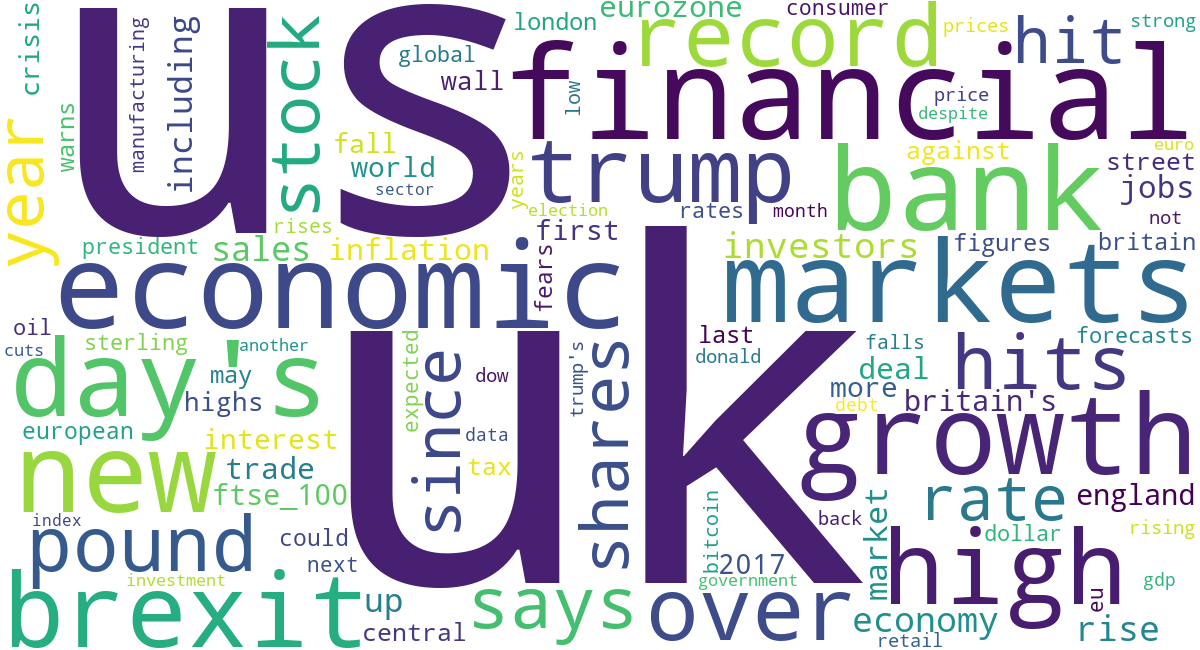

**Broad · 2020**

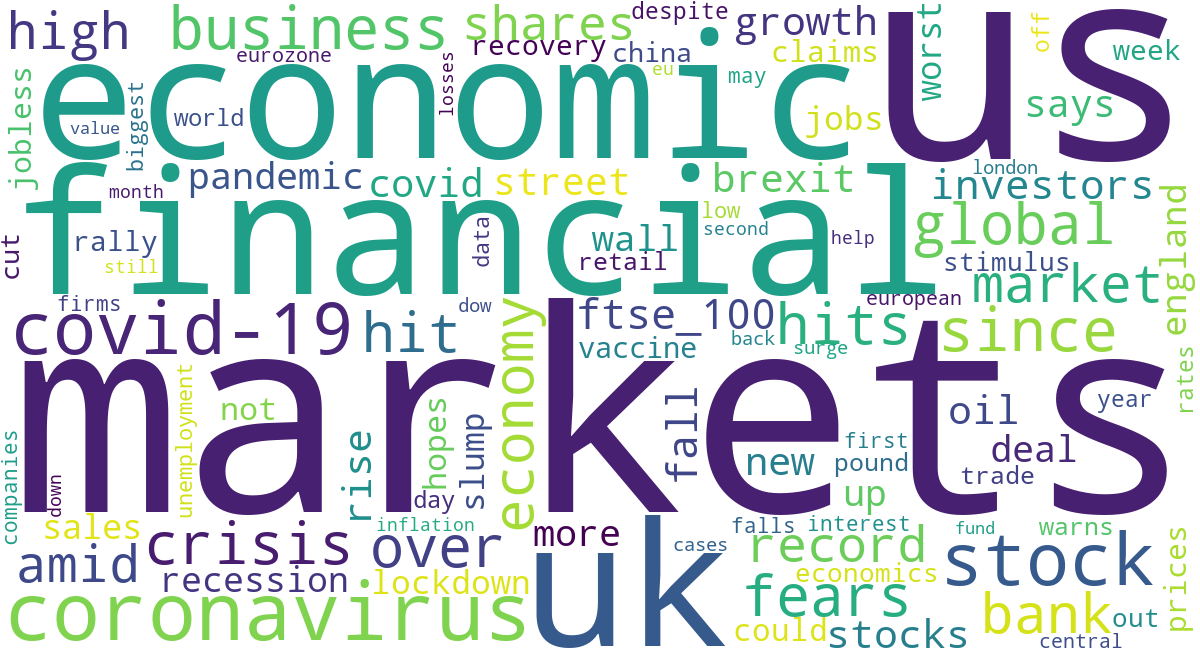

**Broad · 2026**

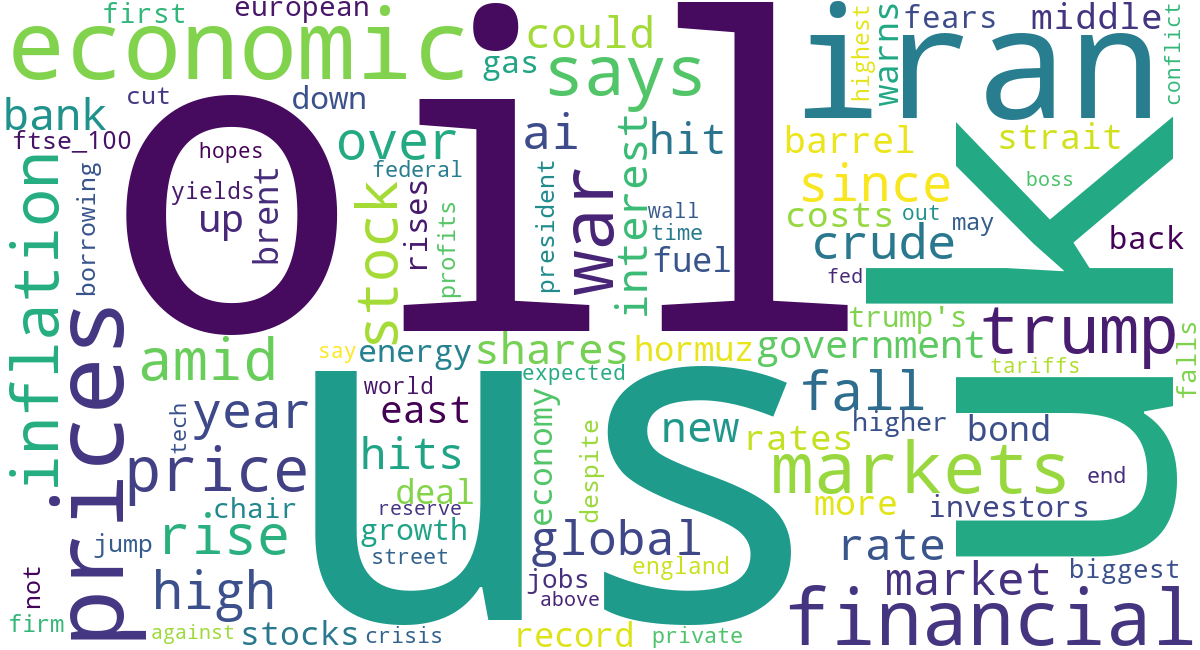

In [6]:
frequencies = read_table("results/guardian_text_final/full_period_word_frequencies.csv", keep_default_na=False)
yearly_frequencies = read_table("results/guardian_text_final/yearly_word_frequencies.csv", keep_default_na=False)
for strategy, flag in FLAGS.items():
    saved = frequencies.loc[frequencies.query_strategy.eq(strategy)]
    assert dict(zip(saved.term, saved["count"])) == dict(token_counters[strategy]), "전체 빈도 불일치"
    for year in range(2017, 2027):
        rows = articles.loc[articles[flag] & articles.year.eq(year)]
        counts = Counter(t for tokens in rows.tokens_clean for t in tokens)
        saved = yearly_frequencies.loc[yearly_frequencies.query_strategy.eq(strategy) & yearly_frequencies.year.eq(year)]
        assert dict(zip(saved.term, saved["count"])) == dict(counts), f"연도별 빈도 불일치: {strategy}, {year}"
display(frequencies.loc[frequencies.query_strategy.eq("broad_business_control")].head(20))
display(yearly_frequencies.loc[yearly_frequencies.query_strategy.eq("broad_business_control")
                              & yearly_frequencies.year.isin([2017, 2020, 2026])].groupby("year").head(10))
for year in [2017, 2020, 2026]:
    display(Markdown(f"**Broad · {year}**"))
    show_figure(f"figures/guardian_text_final/wordcloud_broad_{year}.png", width=850)

## 4. VADER Sentiment Analysis
확정된 VADER 3.3.2를 보존된 `text_sentiment`에 기사별로 적용한다. 사전·규칙·라벨을 수정하지 않는다.
Compound ≥ 0.05는 positive, ≤ −0.05는 negative, 나머지는 neutral이다.

,query_strategy,article_count,mean_compound,positive_count,positive_share,neutral_count,neutral_share,negative_count,negative_share
0,broad_business_control,5054,-0.07818706,2009,0.3975069,517,0.1022952,2528,0.5001979
1,anchors_stock_market_tag,2512,-0.0931873,955,0.3801752,261,0.1039013,1296,0.5159236


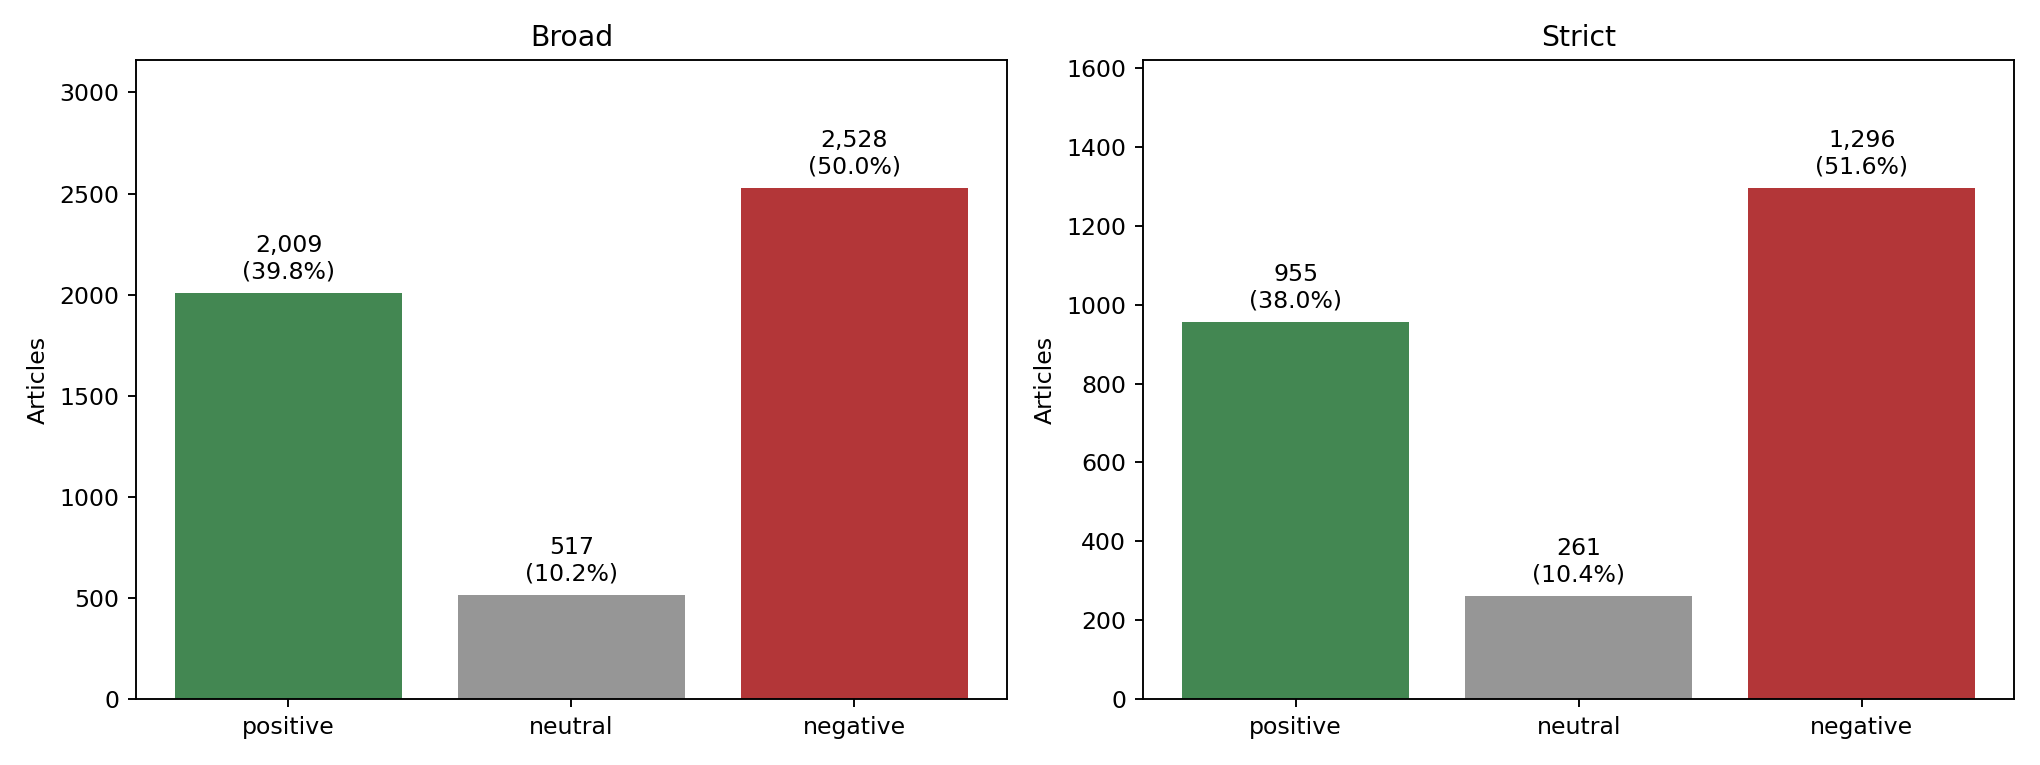

In [7]:
assert importlib.metadata.version("vaderSentiment") == "3.3.2", "VADER 3.3.2가 필요합니다."
analyzer = SentimentIntensityAnalyzer()
scores = pd.DataFrame([analyzer.polarity_scores(text) for text in articles.text_sentiment]).add_prefix("vader_")
articles = pd.concat([articles, scores], axis=1)
articles["sentiment_class"] = np.select([articles.vader_compound.ge(0.05), articles.vader_compound.le(-0.05)],
                                         ["positive", "negative"], default="neutral")
scored_reference = load_parquet("data/processed/guardian_vader/articles", columns=[
    "guardian_id", "vader_neg", "vader_neu", "vader_pos", "vader_compound", "sentiment_class"
]).set_index("guardian_id").reindex(articles.guardian_id)
for column in scores.columns:
    assert np.array_equal(articles[column], scored_reference[column]), f"최종 VADER 점수 불일치: {column}"
assert articles.sentiment_class.tolist() == scored_reference.sentiment_class.tolist(), "최종 감성 분류 불일치"
sentiment_rows = []
for strategy, flag in FLAGS.items():
    subset = articles.loc[articles[flag]]
    row = {"query_strategy": strategy, "article_count": len(subset), "mean_compound": subset.vader_compound.mean()}
    for label in ["positive", "neutral", "negative"]:
        row[label + "_count"] = int(subset.sentiment_class.eq(label).sum())
        row[label + "_share"] = row[label + "_count"] / len(subset)
    sentiment_rows.append(row)
sentiment_summary = pd.DataFrame(sentiment_rows)
sentiment_saved = read_table("results/guardian_sentiment/article_descriptive_statistics.csv").set_index("query_strategy")
for row in sentiment_summary.itertuples():
    for field in sentiment_summary.columns[1:]:
        assert_close(getattr(row, field), sentiment_saved.loc[row.query_strategy, field], field)
display(sentiment_summary)
show_figure("figures/guardian_sentiment/sentiment_class_distribution.png")

## 5. Weekly Web Sentiment Index
뉴욕 월요일~일요일 달력에서 $P_w,N_w,U_w$는 긍정·부정·중립 기사 수이다.

$B_w=(P_w-N_w)/(P_w+N_w+U_w)$, $WSI_{count,w}=50(1+B_w)$.

연속 점수 강건성은 $WSI_{continuous,w}=50(1+\overline{compound}_w)$이다.
경계 포함 513주 중 완전한 주는 512주이다. 기사 0건 주의 감성·WSI는 결측으로 유지한다.

,query_strategy,metric,valid_weeks,missing_weeks,mean,median,std,min,max
0,broad_business_control,WSI_count,512,0,45.39508,45,18.33322,0,100
1,broad_business_control,WSI_continuous,512,0,46.31764,46.80164,10.37764,17.068,73.183
2,anchors_stock_market_tag,WSI_count,504,8,43.63411,41.66667,26.32111,0,100
3,anchors_stock_market_tag,WSI_continuous,504,8,45.52782,45.8105,14.76356,8.875,88.25


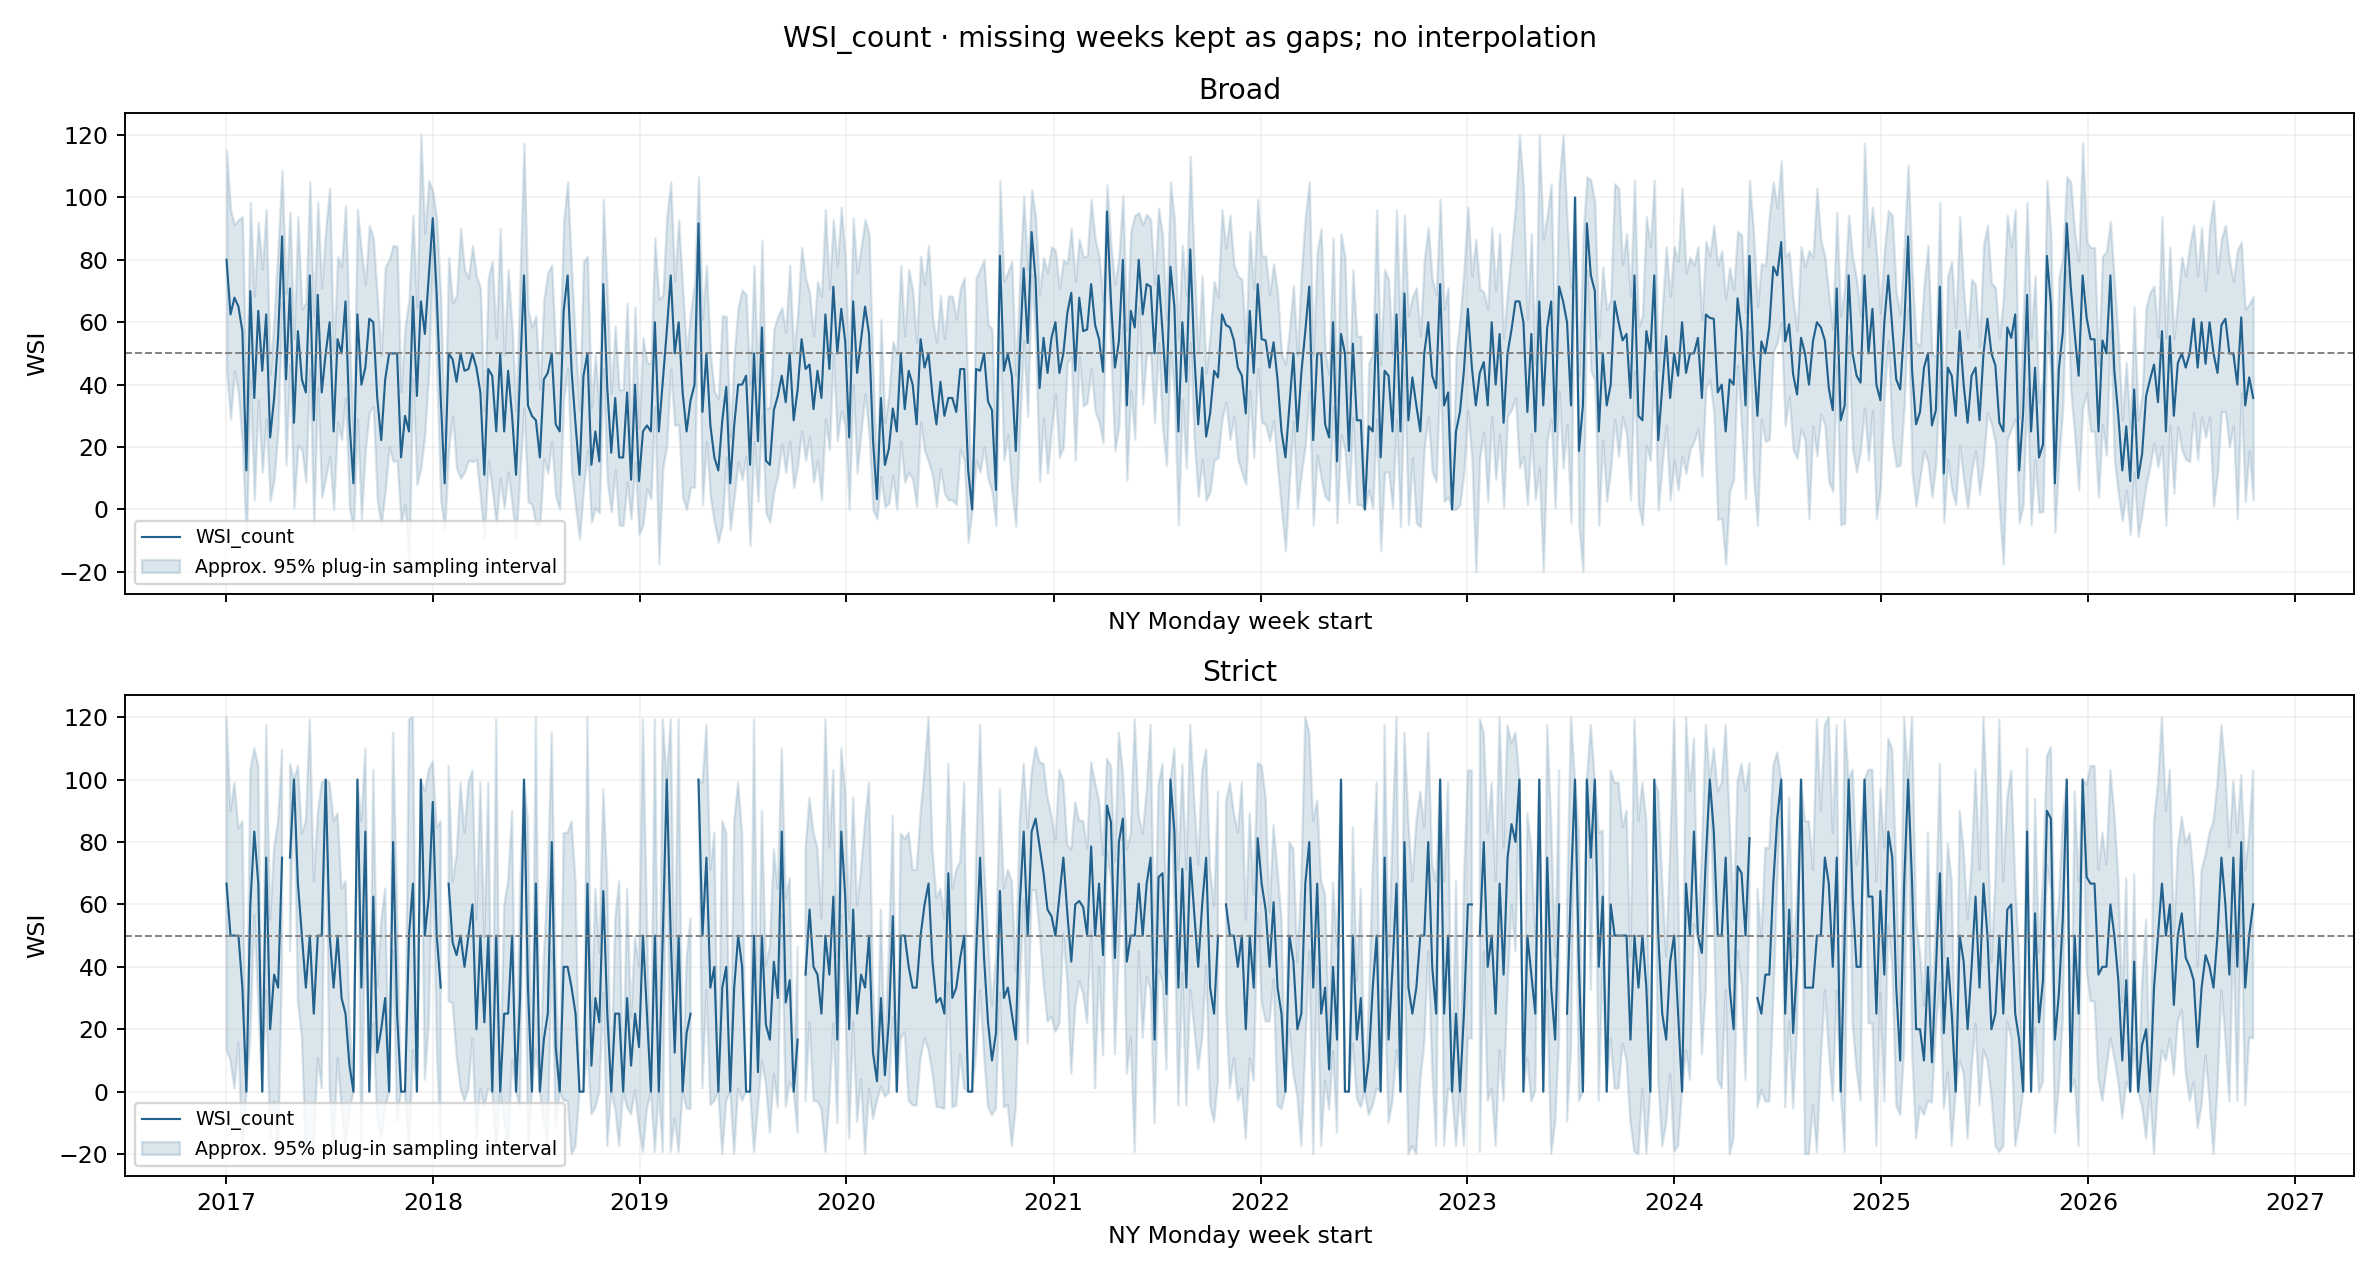

In [8]:
use_file("guardian_weekly_sentiment.py")
from guardian_weekly_sentiment import weekly_sentiment
calendar_source = read_table("results/guardian_text_final/weekly_article_token_counts.csv")
weekly = pd.concat([weekly_sentiment(articles, calendar_source, strategy) for strategy in FLAGS], ignore_index=True)
week_grid = weekly.loc[weekly.query_strategy.eq("broad_business_control")].set_index("week_start")
wide = pd.DataFrame(index=week_grid.index)
wide["is_complete_week"] = week_grid.is_complete_week
for strategy, alias in ALIASES.items():
    current = weekly.loc[weekly.query_strategy.eq(strategy)].set_index("week_start")
    for metric in ["WSI_count", "WSI_continuous"]:
        wide[alias + "_" + metric] = current[metric]
    saved = read_table(f"results/guardian_sentiment/weekly_{alias}_wsi.csv", parse_dates=["week_start"]).set_index("week_start")
    for metric in ["article_count", "WSI_count", "WSI_continuous"]:
        assert_close(current[metric], saved[metric], f"주간 {strategy} {metric}")
weekly_summary_rows = []
for strategy in FLAGS:
    current = weekly.loc[weekly.query_strategy.eq(strategy) & weekly.is_complete_week]
    for metric in ["WSI_count", "WSI_continuous"]:
        values = current[metric].dropna()
        weekly_summary_rows.append({"query_strategy": strategy, "metric": metric, "valid_weeks": len(values),
            "missing_weeks": int(current[metric].isna().sum()), "mean": values.mean(), "median": values.median(),
            "std": values.std(ddof=1), "min": values.min(), "max": values.max()})
weekly_summary = pd.DataFrame(weekly_summary_rows)
saved_summary = read_table("results/guardian_sentiment/weekly_descriptive_statistics.csv")
saved_summary = saved_summary.loc[saved_summary.scope.eq("complete_weeks")].set_index(["query_strategy", "metric"])
for row in weekly_summary.to_dict("records"):
    saved = saved_summary.loc[(row["query_strategy"], row["metric"])]
    for field in ["valid_weeks", "missing_weeks", "mean", "median", "std", "min", "max"]:
        assert_close(row[field], saved[field], f"주간 summary {field}")
display(weekly_summary)
show_figure("figures/guardian_sentiment/weekly_wsi_count.png", width=1150)

## 6. Fear & Greed Index Validation
보관한 일별 FGI 2,443개를 읽고 같은 주의 관측값 평균을 사용한다. 재다운로드·보간·전방 채움은 없다.
날짜 라벨을 UTC 자정으로 바꾸지 않는다. FGI는 정답 라벨이 아니며, 기존 자료 계보 차이는 유지한다.
본 제출본의 상관계수는 **Pearson만** 사용한다.

,observations,first_date,last_date,duplicate_dates,missing_values
0,2443,2017-01-03,2026-10-23,0,0


,FGI_weekly_mean,FGI_observation_count
week_start,,
2016-12-26,NaN,0
2017-01-02,70,4
2017-01-09,60.2,5
2017-01-16,55,4
2017-01-23,56.2,5
2017-01-30,54.2,5
2017-02-06,62.2,5
2017-02-13,77.6,5


,FGI_weekly_mean,FGI_observation_count,is_complete_week
week_start,,,
2016-12-26,NaN,0,False
2020-06-08,NaN,0,True
2020-06-15,NaN,0,True
2020-06-22,NaN,0,True
2020-06-29,NaN,0,True


,query_strategy,WSI_metric,n_pairs,pearson
0,broad_business_control,WSI_count,508,0.2247696
1,broad_business_control,WSI_continuous,508,0.2285988
2,anchors_stock_market_tag,WSI_count,500,0.1418666
3,anchors_stock_market_tag,WSI_continuous,500,0.1510564


,specification,R_squared
0,Broad count / weekly mean FGI,0.05052135


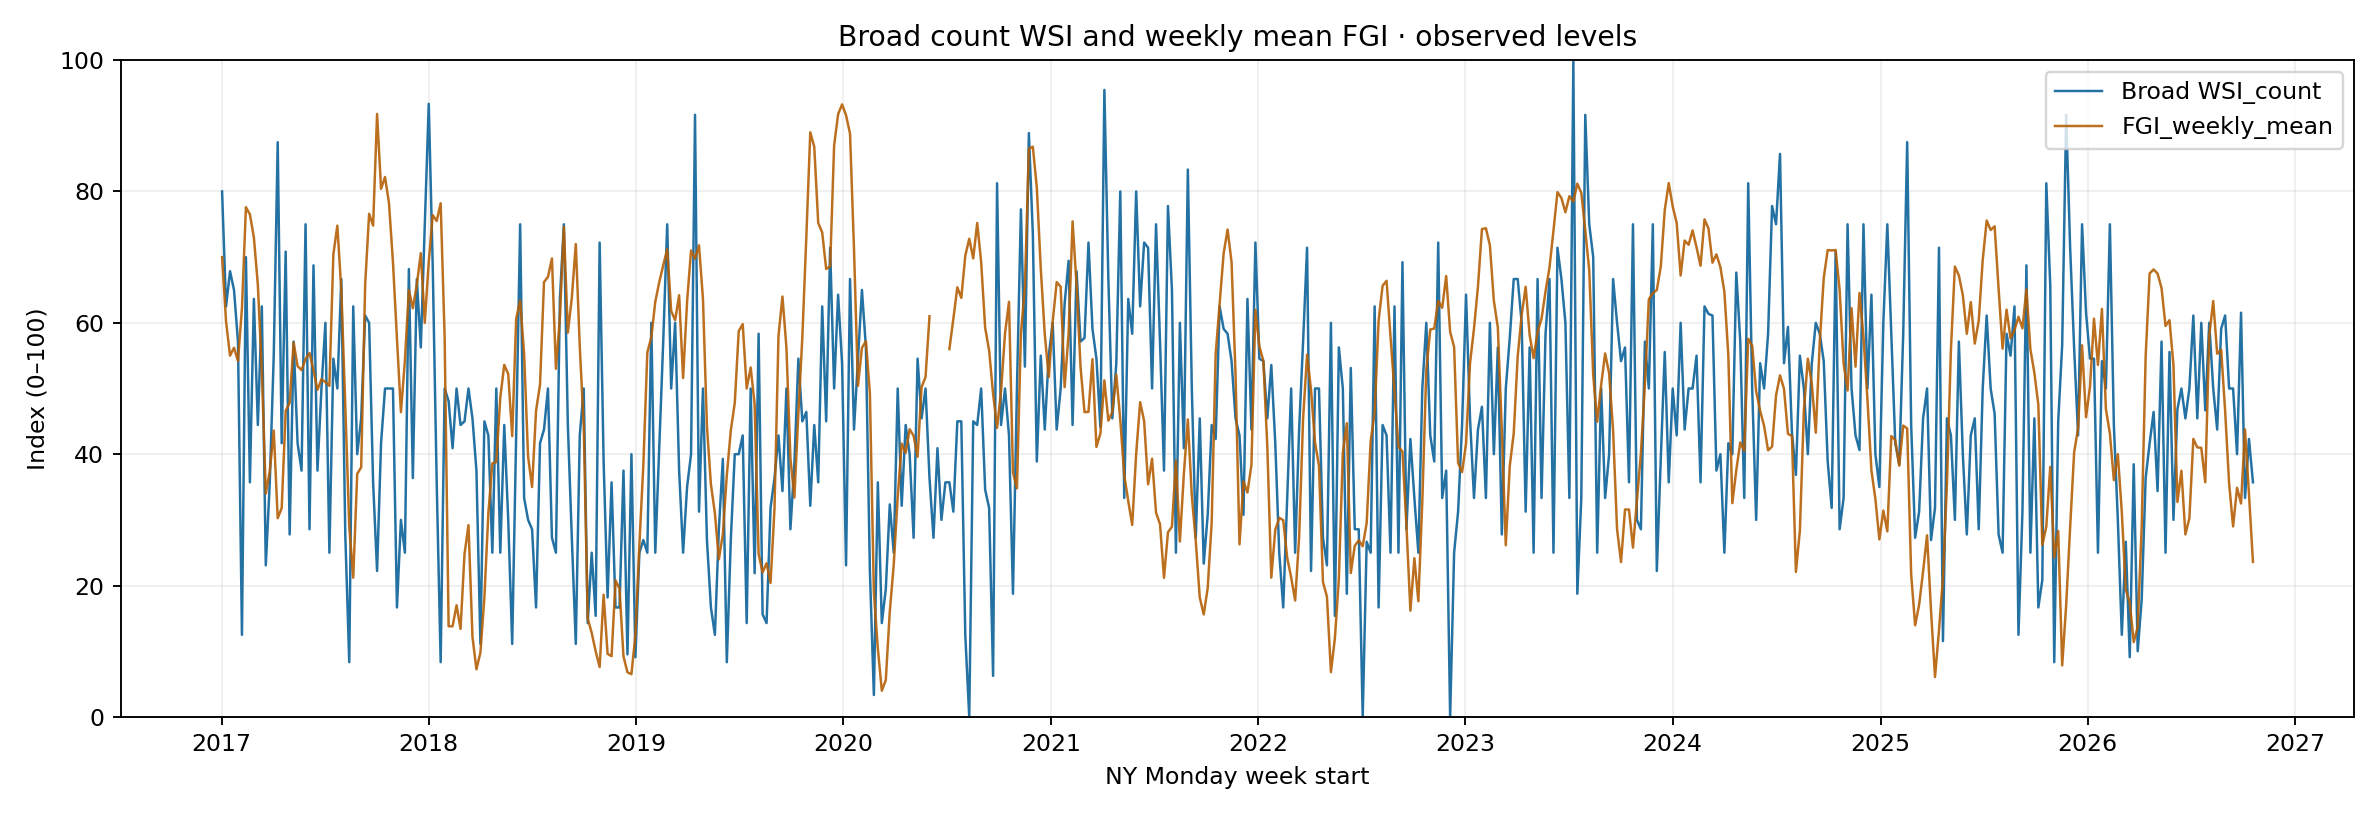

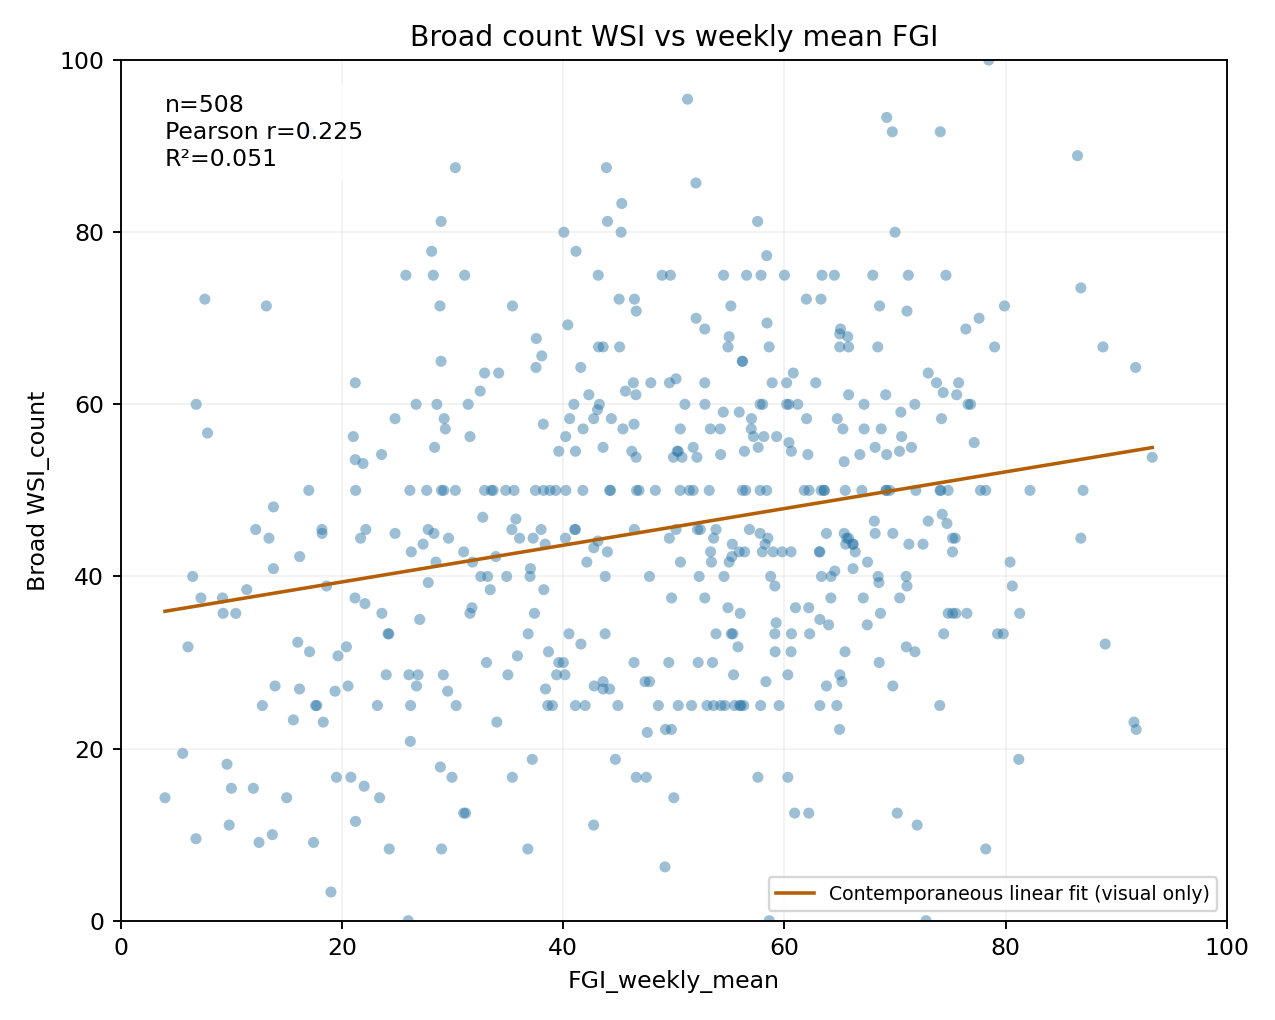

In [9]:
fgi_daily = read_table("data/external/fear_greed_2017-01-01_2026-10-25.csv", parse_dates=["date"])
assert fgi_daily.date.is_unique and fgi_daily.fgi.notna().all(), "FGI 중복·결측 점검 실패"
assert fgi_daily.date.between(START, END).all(), "FGI 기간 오류"
fgi_diagnostics = pd.DataFrame([{"observations": len(fgi_daily), "first_date": fgi_daily.date.min().date(),
                                "last_date": fgi_daily.date.max().date(), "duplicate_dates": int(fgi_daily.date.duplicated().sum()),
                                "missing_values": int(fgi_daily.fgi.isna().sum())}])
fgi_daily["week_start"] = fgi_daily.date - pd.to_timedelta(fgi_daily.date.dt.weekday, unit="D")
fgi_weekly = fgi_daily.groupby("week_start").agg(FGI_weekly_mean=("fgi", "mean"), FGI_observation_count=("fgi", "count"))
fgi_weekly = fgi_weekly.reindex(wide.index)
fgi_weekly["FGI_observation_count"] = fgi_weekly.FGI_observation_count.fillna(0).astype(int)
saved_fgi = read_table("results/guardian_fgi_validation/fgi_weekly_validated.csv", parse_dates=["week_start"]).set_index("week_start")
for column in ["FGI_weekly_mean", "FGI_observation_count"]:
    assert_close(fgi_weekly[column], saved_fgi[column], column)
wide["FGI_weekly_mean"] = fgi_weekly.FGI_weekly_mean
display(fgi_diagnostics)
display(fgi_weekly.head(8))
display(fgi_weekly.loc[fgi_weekly.FGI_observation_count.eq(0)].join(wide[["is_complete_week"]]))

def pearson_pair(x, y):
    paired = pd.DataFrame({"x": x, "y": y}).dropna()
    return len(paired), paired.x.corr(paired.y, method="pearson")

FEATURES = {f"{alias}_{metric}": (strategy, metric) for strategy, alias in ALIASES.items()
            for metric in ["WSI_count", "WSI_continuous"]}
fgi_correlations = []
for feature, (strategy, metric) in FEATURES.items():
    current = wide.loc[wide.is_complete_week]
    n, r = pearson_pair(current[feature], current.FGI_weekly_mean)
    fgi_correlations.append({"query_strategy": strategy, "WSI_metric": metric, "n_pairs": n, "pearson": r})
fgi_correlations = pd.DataFrame(fgi_correlations)
saved_corr = read_table("results/guardian_fgi_validation/contemporaneous_correlations.csv",
                       usecols=["query_strategy", "WSI_metric", "FGI_metric", "n_pairs", "pearson"])
saved_corr = saved_corr.loc[saved_corr.FGI_metric.eq("FGI_weekly_mean")].set_index(["query_strategy", "WSI_metric"])
for row in fgi_correlations.itertuples():
    saved = saved_corr.loc[(row.query_strategy, row.WSI_metric)]
    assert row.n_pairs == saved.n_pairs, "FGI 유효 쌍 수 불일치"
    assert_close(row.pearson, saved.pearson, "WSI-FGI Pearson")
primary_fgi_r = fgi_correlations.loc[fgi_correlations.query_strategy.eq("broad_business_control")
                                    & fgi_correlations.WSI_metric.eq("WSI_count"), "pearson"].iloc[0]
primary_fgi_r2 = primary_fgi_r ** 2  # R² of the existing simple contemporaneous fit with intercept.
saved_fgi_fit = read_json("results/guardian_fgi_validation/scatter_visual_fit.json")
assert_close(primary_fgi_r2, saved_fgi_fit["R_squared"], "WSI-FGI R²")
display(fgi_correlations)
display(pd.DataFrame([{"specification": "Broad count / weekly mean FGI", "R_squared": primary_fgi_r2}]))
show_figure("figures/guardian_fgi_validation/wsi_fgi_overlay_0_100.png", width=1150)
show_figure("figures/guardian_fgi_validation/wsi_fgi_scatter.png", width=800)

## 7. Lead-Lag Analysis · Pearson Only
$\rho(k)=Corr(WSI_w,FGI_{w+k})$, $k=-4,\ldots,+4$이다.
양수 k는 현재 WSI와 이후 FGI, 음수 k는 현재 WSI와 이전 FGI를 비교한다.
달력 주를 유지한 채 날짜 키를 맞추고 결측 쌍을 제외한다. 최고 상관 시차는 인과·예측의 증거가 아니다.
그림은 저장된 최종 Pearson 값만 표시하며 별도 분석 파일을 생성하지 않는다.

,query_strategy,WSI_metric,lag_weeks,n_pairs,pearson
0,anchors_stock_market_tag,WSI_continuous,1,499,0.1617253
1,anchors_stock_market_tag,WSI_count,1,499,0.1499156
2,broad_business_control,WSI_continuous,0,508,0.2285988
3,broad_business_control,WSI_count,0,508,0.2247696


,query_strategy,WSI_metric,lag_weeks,n_pairs,pearson
0,broad_business_control,WSI_count,-4,504,0.09009189
1,broad_business_control,WSI_count,-3,505,0.1016723
2,broad_business_control,WSI_count,-2,506,0.1107868
3,broad_business_control,WSI_count,-1,507,0.1508454
4,broad_business_control,WSI_count,0,508,0.2247696
5,broad_business_control,WSI_count,1,507,0.2221363
6,broad_business_control,WSI_count,2,506,0.1634317
7,broad_business_control,WSI_count,3,505,0.1238417
8,broad_business_control,WSI_count,4,504,0.03935868


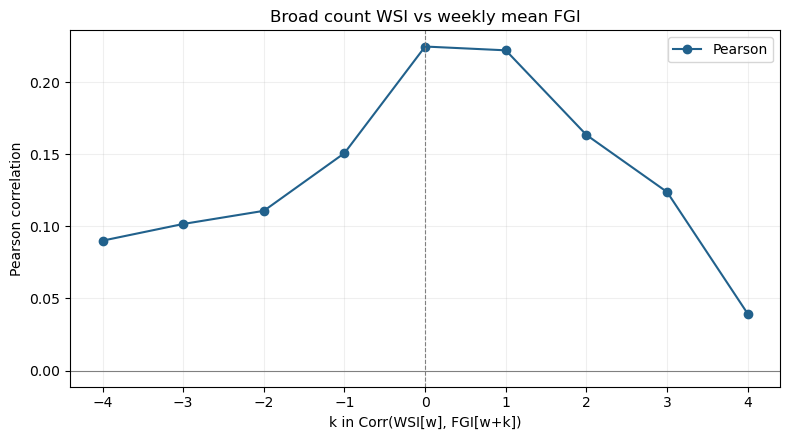

,WSI_metric,lag_weeks,n_pairs,pearson
0,WSI_count,0,506,0.1102837
1,WSI_continuous,0,506,0.1301129


In [10]:
def calendar_shift(series, lag):
    shifted = series.reindex(wide.index + pd.Timedelta(weeks=lag)).copy()
    shifted.index = wide.index
    return shifted

level_rows = []
fgi_level = wide.FGI_weekly_mean.where(wide.is_complete_week)
for feature, (strategy, metric) in FEATURES.items():
    x = wide[feature].where(wide.is_complete_week)
    for lag in range(-4, 5):
        n, r = pearson_pair(x, calendar_shift(fgi_level, lag))
        level_rows.append({"query_strategy": strategy, "WSI_metric": metric, "lag_weeks": lag,
                           "n_pairs": n, "pearson": r})
lead_lag = pd.DataFrame(level_rows)
saved_lags = read_table("results/guardian_fgi_validation/lead_lag_correlations.csv",
                       usecols=["query_strategy", "WSI_metric", "lag_weeks", "n_pairs", "pearson"])
keys = ["query_strategy", "WSI_metric", "lag_weeks"]
aligned = lead_lag.merge(saved_lags, on=keys, suffixes=("", "_saved"), validate="one_to_one")
assert aligned.n_pairs.eq(aligned.n_pairs_saved).all(), "시차 유효 쌍 수 불일치"
assert_close(aligned.pearson, aligned.pearson_saved, "시차 Pearson")
peak_indices = lead_lag.groupby(["query_strategy", "WSI_metric"]).pearson.apply(lambda values: values.abs().idxmax())
strongest_lags = lead_lag.loc[peak_indices.to_list()].reset_index(drop=True)
display(strongest_lags)
primary_lags = saved_lags.loc[saved_lags.query_strategy.eq("broad_business_control")
                              & saved_lags.WSI_metric.eq("WSI_count")].sort_values("lag_weeks")
display(primary_lags)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(primary_lags.lag_weeks, primary_lags.pearson, marker="o", color="#21618c", label="Pearson")
ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)
ax.axhline(0, color="gray", linewidth=0.8)
ax.set(title="Broad count WSI vs weekly mean FGI", xlabel="k in Corr(WSI[w], FGI[w+k])",
       ylabel="Pearson correlation", xticks=range(-4, 5))
ax.grid(alpha=0.2); ax.legend(); fig.tight_layout()
plt.show()

difference_rows = []
for metric in ["WSI_count", "WSI_continuous"]:
    x = wide["broad_" + metric].where(wide.is_complete_week).diff()
    y = fgi_level.diff()  # Missing either adjacent calendar week leaves the difference missing.
    n, r = pearson_pair(x, y)
    difference_rows.append({"WSI_metric": metric, "lag_weeks": 0, "n_pairs": n, "pearson": r})
difference_summary = pd.DataFrame(difference_rows)
saved_differences = read_table("results/guardian_fgi_validation/first_difference_robustness.csv",
                              usecols=["query_strategy", "WSI_metric", "lag_weeks", "n_pairs", "pearson"])
saved_differences = saved_differences.loc[saved_differences.query_strategy.eq("broad_business_control")
                                        & saved_differences.lag_weeks.eq(0)].set_index("WSI_metric")
for row in difference_summary.itertuples():
    assert row.n_pairs == saved_differences.loc[row.WSI_metric, "n_pairs"]
    assert_close(row.pearson, saved_differences.loc[row.WSI_metric, "pearson"], "1차 차분 Pearson")
display(difference_summary)

## 8. S&P 500 Market Analysis
저장된 **FRED SP500 종가**만 사용한다. 배당 미포함 가격지수이며 수정종가를 임의 생성하지 않는다.
$r_w=\ln(P_w/P_{w-1})$에서 $P_w$는 해당 주 마지막 유효 종가이다.
첫 주의 직전 가격, 빈 주, 표본 종료 후 다음 주 수익률을 채우지 않는다.
동시점·탐색적 다음 주 모형은 각각 절편과 설명변수 하나의 기존 OLS 명세이다.
Conventional p값은 자기상관·이분산에 강건하지 않으며 인과·예측·거래 능력을 의미하지 않는다.

,daily_prices,first_date,last_date,weekly_returns
0,2466,2017-01-03,2026-10-23,511


,predictor,n_pairs,pearson,alpha,beta,se_beta,t_beta,p_value_beta_two_sided,R_squared,adjusted_R_squared
relationship,,,,,,,,,,
contemporaneous,broad_WSI_count,511,0.1773379,-0.008185427,0.0002327561,5.725349e-05,4.065362,5.555081e-05,0.03144874,0.02954589
exploratory_next_week,broad_WSI_count,511,-0.01093186,0.003014294,-1.430177e-05,5.798439e-05,-0.2466487,0.8052796,0.0001195055,-0.001844896


,predictor,relationship,n_pairs,pearson,beta,p_value_beta_two_sided,R_squared
0,broad_WSI_count,contemporaneous,511,0.1773379,0.0002327561,5.555081e-05,0.03144874
1,broad_WSI_count,exploratory_next_week,511,-0.01093186,-1.430177e-05,0.8052796,0.0001195055
2,broad_WSI_continuous,contemporaneous,511,0.2083721,0.0004835859,2.023844e-06,0.04341893
3,broad_WSI_continuous,exploratory_next_week,511,-0.01055181,-2.44045e-05,0.8119203,0.0001113407
4,FGI_weekly_mean,contemporaneous,507,0.1880219,0.0002318594,2.032971e-05,0.03535223
5,FGI_weekly_mean,exploratory_next_week,507,-0.0428334,-5.306513e-05,0.3357852,0.0018347


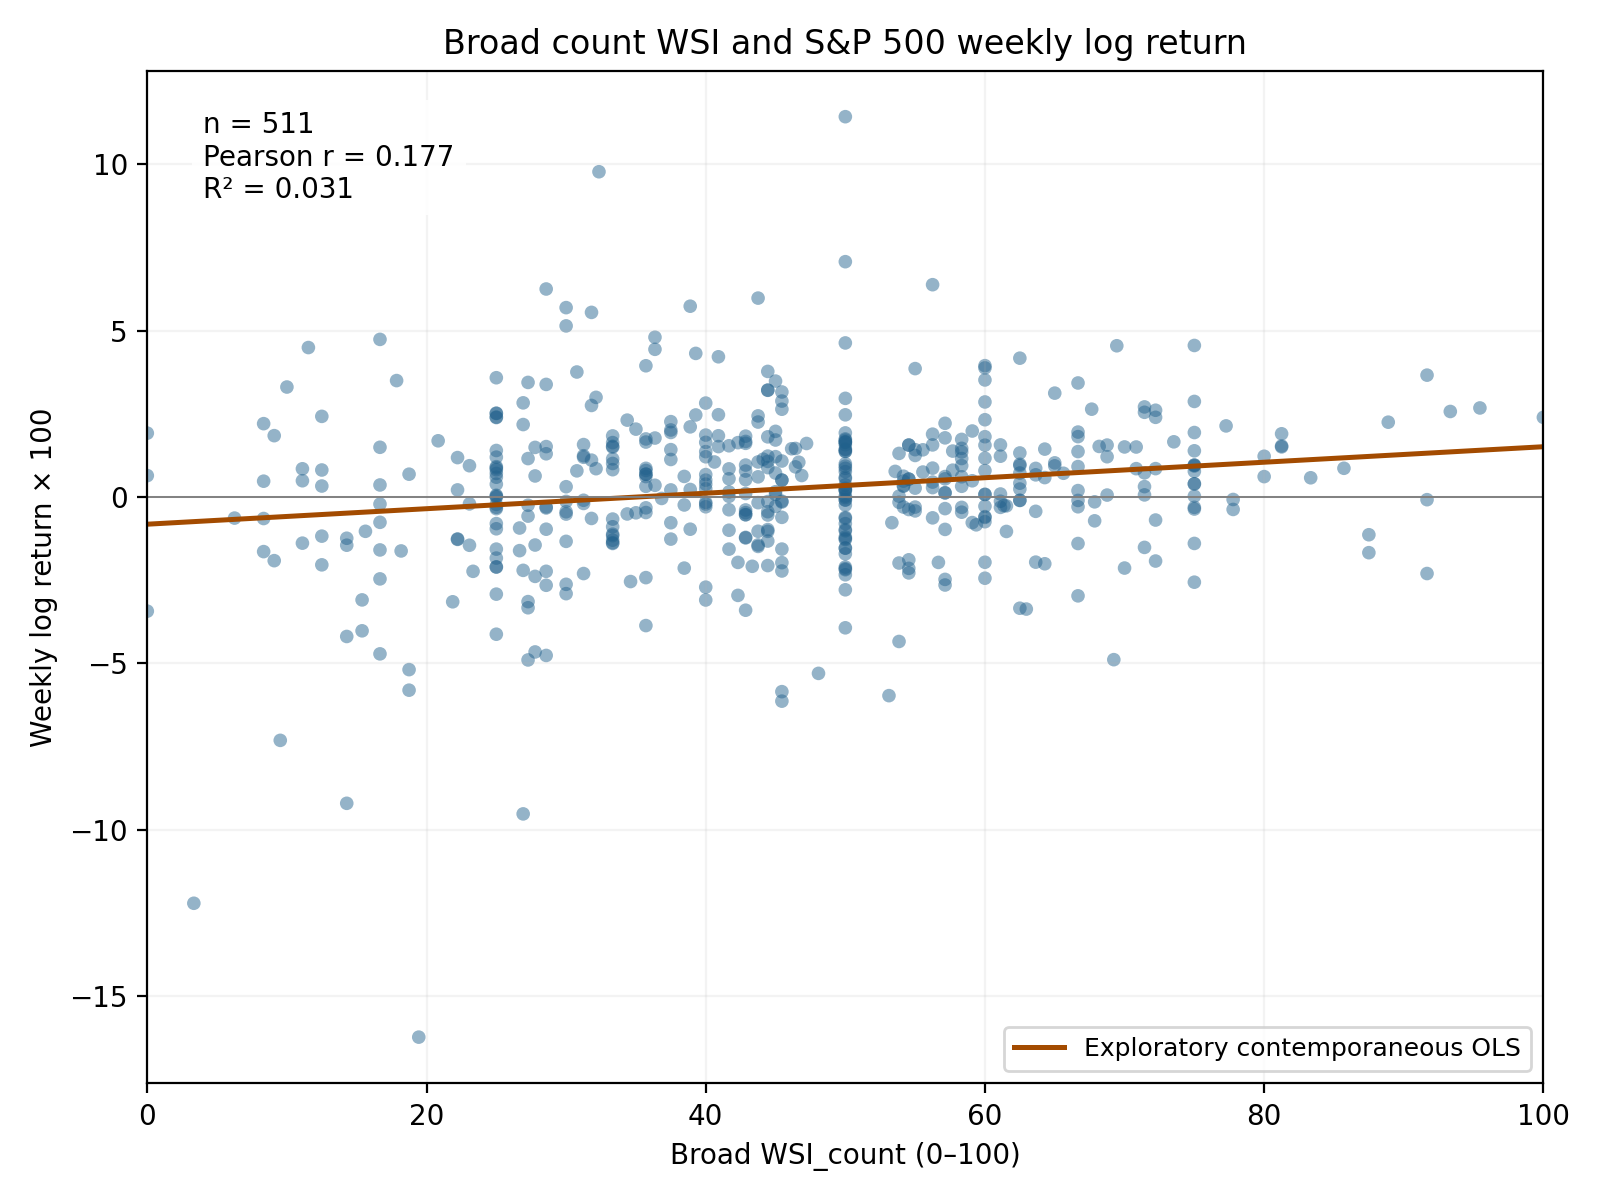

In [11]:
market_raw = read_table("data/raw/market/fred_sp500_2017-01-01_2026-10-25.csv",
                        parse_dates=["observation_date"], na_values=["."])
prices = market_raw.loc[market_raw.observation_date.between(START, END) & market_raw.SP500.notna()].copy()
assert prices.observation_date.is_unique and prices.SP500.gt(0).all(), "시장 가격 검증 실패"
prices = prices.sort_values("observation_date")
prices["week_start"] = prices.observation_date - pd.to_timedelta(prices.observation_date.dt.weekday, unit="D")
weekly_price = prices.groupby("week_start").SP500.last().reindex(wide.index)
market_return = np.log(weekly_price / weekly_price.shift(1))
saved_market = read_table("results/guardian_market_analysis/sp500_weekly_returns.csv", parse_dates=["week_start"]).set_index("week_start")
assert_close(weekly_price, saved_market.weekly_close, "주간 종가")
assert_close(market_return, saved_market.weekly_log_return, "주간 로그수익률")
wide["weekly_log_return"] = market_return
wide["next_week_log_return"] = calendar_shift(market_return, 1)
display(pd.DataFrame([{"daily_prices": len(prices), "first_date": prices.observation_date.min().date(),
                       "last_date": prices.observation_date.max().date(), "weekly_returns": int(market_return.notna().sum())}]))

market_rows = []
for predictor in ["broad_WSI_count", "broad_WSI_continuous", "FGI_weekly_mean"]:
    for relationship, target in [("contemporaneous", "weekly_log_return"),
                                  ("exploratory_next_week", "next_week_log_return")]:
        paired = wide.loc[wide.is_complete_week, [predictor, target]].dropna()
        fit = linregress(paired[predictor], paired[target])
        n = len(paired)
        market_rows.append({"predictor": predictor, "relationship": relationship, "n_pairs": n,
            "pearson": fit.rvalue, "alpha": fit.intercept, "beta": fit.slope, "se_beta": fit.stderr,
            "t_beta": fit.slope / fit.stderr, "p_value_beta_two_sided": fit.pvalue,
            "R_squared": fit.rvalue ** 2, "adjusted_R_squared": 1 - (1 - fit.rvalue ** 2) * (n - 1) / (n - 2)})
market_results = pd.DataFrame(market_rows)
saved_ols = read_table("results/guardian_market_analysis/market_OLS_results.csv",
                      usecols=["predictor", "relationship", "n_observations", "alpha", "beta", "se_beta", "t_beta",
                               "p_value_beta_two_sided", "R_squared", "adjusted_R_squared"]).set_index(["predictor", "relationship"])
saved_market_corr = read_table("results/guardian_market_analysis/market_correlations.csv",
                              usecols=["predictor", "relationship", "n_pairs", "pearson"]).set_index(["predictor", "relationship"])
for row in market_results.to_dict("records"):
    key = (row["predictor"], row["relationship"])
    assert row["n_pairs"] == saved_ols.loc[key, "n_observations"]
    for field in ["alpha", "beta", "se_beta", "t_beta", "p_value_beta_two_sided", "R_squared", "adjusted_R_squared"]:
        assert_close(row[field], saved_ols.loc[key, field], f"시장 OLS {key} {field}")
    assert_close(row["pearson"], saved_market_corr.loc[key, "pearson"], "시장 Pearson")
primary_market = market_results.loc[market_results.predictor.eq("broad_WSI_count")].set_index("relationship")
display(primary_market)
display(market_results[["predictor", "relationship", "n_pairs", "pearson", "beta", "p_value_beta_two_sided", "R_squared"]])
show_figure("figures/guardian_market_analysis/market_broad_count_scatter.png", width=900)

## 9. Final Results Summary
보고서의 주 명세 수치를 한 표에 모은다. 추가 결론이나 새로운 해석은 작성하지 않는다.

In [12]:
same = primary_market.loc["contemporaneous"]
following = primary_market.loc["exploratory_next_week"]
broad_peak = strongest_lags.loc[strongest_lags.query_strategy.eq("broad_business_control")
                                & strongest_lags.WSI_metric.eq("WSI_count")].iloc[0]
final_results = pd.DataFrame([
    {"result": "Broad count WSI / weekly mean FGI Pearson", "value": primary_fgi_r},
    {"result": "Broad count WSI / FGI contemporaneous R_squared", "value": primary_fgi_r2},
    {"result": "Strongest broad count lead-lag (weeks)", "value": int(broad_peak.lag_weeks)},
    {"result": "Broad count / S&P 500 same-week Pearson", "value": same.pearson},
    {"result": "Broad count / S&P 500 same-week R_squared", "value": same.R_squared},
    {"result": "Broad count / S&P 500 next-week Pearson", "value": following.pearson},
    {"result": "Broad count / S&P 500 next-week R_squared", "value": following.R_squared},
])
display(final_results)

,result,value
0,Broad count WSI / weekly mean FGI Pearson,0.2247696
1,Broad count WSI / FGI contemporaneous R_squared,0.05052135
2,Strongest broad count lead-lag (weeks),0
3,Broad count / S&P 500 same-week Pearson,0.1773379
4,Broad count / S&P 500 same-week R_squared,0.03144874
5,Broad count / S&P 500 next-week Pearson,-0.01093186
6,Broad count / S&P 500 next-week R_squared,0.0001195055


## 10. Validation Checks
원자료·중간 결과의 정확한 대조와 보고서 반올림 수치의 허용오차 검증이다.
입력 해시도 다시 확인한다. 실패 시 명확한 AssertionError를 발생시킨다.

In [13]:
def near(value, expected):
    return bool(np.isclose(value, expected, rtol=0, atol=5e-5))

counts = sentiment_summary.set_index("query_strategy")
tokens = token_summary.set_index("query_strategy")
fgi_index = fgi_correlations.set_index(["query_strategy", "WSI_metric"])
peaks = strongest_lags.set_index(["query_strategy", "WSI_metric"])
differences = difference_summary.set_index("WSI_metric")
checks = {
    "Guardian unique articles = 5265": len(raw) == 5265,
    "Broad / strict / overlap = 5054 / 2512 / 2301": (int(raw.in_broad_business_control.sum()), int(raw.in_anchors_stock_market_tag.sum()), int(raw[list(FLAGS.values())].all(axis=1).sum())) == (5054, 2512, 2301),
    "Missing title / description = 0": int(raw_diagnostics.missing_title.iloc[0]) == int(raw_diagnostics.missing_description.iloc[0]) == 0,
    "Final clean tokens / vocabulary preserved": (int(tokens.loc["broad_business_control", "clean_token_count"]), int(tokens.loc["broad_business_control", "vocabulary_count"]), int(tokens.loc["anchors_stock_market_tag", "clean_token_count"]), int(tokens.loc["anchors_stock_market_tag", "vocabulary_count"])) == (106612, 12550, 53282, 7332),
    "Broad sentiment counts = 2009 / 517 / 2528": tuple(int(counts.loc["broad_business_control", c + "_count"]) for c in ["positive", "neutral", "negative"]) == (2009, 517, 2528),
    "Strict sentiment counts = 955 / 261 / 1296": tuple(int(counts.loc["anchors_stock_market_tag", c + "_count"]) for c in ["positive", "neutral", "negative"]) == (955, 261, 1296),
    "Mean compounds = -0.0782 / -0.0932": near(counts.loc["broad_business_control", "mean_compound"], -0.0782) and near(counts.loc["anchors_stock_market_tag", "mean_compound"], -0.0932),
    "Complete broad weeks = 512; strict missing weeks = 8": int(wide.is_complete_week.sum()) == 512 and int(wide.loc[wide.is_complete_week, "strict_WSI_count"].isna().sum()) == 8,
    "FGI observations = 2443; empty complete weeks = 4": len(fgi_daily) == 2443 and int((fgi_weekly.FGI_observation_count.eq(0) & wide.is_complete_week).sum()) == 4,
    "FGI Pearson = 0.2248 / 0.2286 / 0.1419 / 0.1511": all(near(fgi_index.loc[(s, m), "pearson"], expected) for s, m, expected in [("broad_business_control", "WSI_count", .2248), ("broad_business_control", "WSI_continuous", .2286), ("anchors_stock_market_tag", "WSI_count", .1419), ("anchors_stock_market_tag", "WSI_continuous", .1511)]),
    "WSI-FGI R_squared = 0.0505": near(primary_fgi_r2, .0505),
    "Strongest broad k = 0; strict k = +1": all(int(peaks.loc[(s, m), "lag_weeks"]) == expected for s, expected in [("broad_business_control", 0), ("anchors_stock_market_tag", 1)] for m in ["WSI_count", "WSI_continuous"]),
    "Strict peak Pearson = 0.1499 / 0.1617": near(peaks.loc[("anchors_stock_market_tag", "WSI_count"), "pearson"], .1499) and near(peaks.loc[("anchors_stock_market_tag", "WSI_continuous"), "pearson"], .1617),
    "First-difference Pearson = 0.1103 / 0.1301": near(differences.loc["WSI_count", "pearson"], .1103) and near(differences.loc["WSI_continuous", "pearson"], .1301),
    "Market daily prices = 2466; weekly returns = 511": len(prices) == 2466 and int(market_return.notna().sum()) == 511,
    "Same-week n=511, r=0.1773, R_squared=0.0314": int(same.n_pairs) == 511 and near(same.pearson, .1773) and near(same.R_squared, .0314),
    "Same-week beta=0.0002328 and p<0.001": bool(np.isclose(same.beta, .0002328, rtol=0, atol=5e-8)) and same.p_value_beta_two_sided < .001,
    "Next-week n=511, r=-0.0109, R_squared about 0.0001": int(following.n_pairs) == 511 and near(following.pearson, -.0109) and near(following.R_squared, .0001),
    "Next-week beta about -0.000014 and p=0.8053": bool(np.isclose(following.beta, -.000014, rtol=0, atol=5e-7)) and near(following.p_value_beta_two_sided, .8053),
    "All input files unchanged": all(hashlib.sha256((PROJECT / relative).read_bytes()).hexdigest() == digest for relative, digest in input_hashes.items()),
    "Historical API collection disabled": NETWORK_COLLECTION_ENABLED is False,
}
for label, passed in checks.items():
    assert bool(passed), f"최종 제출 검증 실패: {label}"
display(pd.DataFrame({"validation_check": list(checks), "result": ["PASS"] * len(checks)}))

,validation_check,result
0,Guardian unique articles = 5265,PASS
1,Broad / strict / overlap = 5054 / 2512 / 2301,PASS
2,Missing title / description = 0,PASS
3,Final clean tokens / vocabulary preserved,PASS
4,Broad sentiment counts = 2009 / 517 / 2528,PASS
5,Strict sentiment counts = 955 / 261 / 1296,PASS
6,Mean compounds = -0.0782 / -0.0932,PASS
7,Complete broad weeks = 512; strict missing weeks = 8,PASS
8,FGI observations = 2443; empty complete weeks = 4,PASS
9,FGI Pearson = 0.2248 / 0.2286 / 0.1419 / 0.1511,PASS
